# 5D KL: PCA contributions and computational time

Four single-run results, fixed p=10, N=3010 to 8000, batches of 10. PCA ratios refer to the last selection at N=7990. Timings are single-thread process CPU times, excluding test diagnostics and preparation.

In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
import sys, csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import FuncNorm
from matplotlib.ticker import FuncFormatter, FormatStrFormatter
from IPython.display import display
HERE=Path.cwd()
if not (HERE.parent/'PCA_Theta.py').exists(): HERE=HERE/'RandomField_5D'
ROOT=HERE
DATA=HERE/'Data'
FIG=HERE/'Figures'
FIG.mkdir(exist_ok=True)
sys.path.insert(0,str(HERE.parent))
from PCA_Theta import load_result
METHODS=['random_ols','lhs_ols','theta_ols','pca_theta_ols','qv_theta_ols','qv_pca_theta_ols']
LABELS=['Random-OLS','LHS-OLS',r'$\Theta$-OLS',r'PCA-$\Theta$-OLS',r'$\eta$-$\Theta$-OLS',r'$\eta$-PCA-$\Theta$-OLS']
COLORS=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#17becf']
CONTRAST_POWER=2.0

In [2]:
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'mathtext.fontset':'stix','font.size':14,'legend.fontsize':14,'legend.frameon':False,'pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False})
PHASES = [
    ("Degree selection and OLS", "#79A7CF", ["degree_selection_and_ols"]),
    ("PCA", "#9977B6", ["pca_and_common_basis"]),
    (r"$\Theta$ sampling", "#E99750", ["criterion_response_evaluation", "distance_search", "criterion_aggregation_and_batch"]),
    ("Model evaluation and other", "#ABACB3", ["model_evaluation", "other"]),
]


def export(fig, name, folder=FIG):
    fig.savefig(folder / (name + ".pdf"), dpi=260, facecolor="white")
    display(fig); plt.close(fig)
def pca_axes(breakdown=False):
    fig = plt.figure(figsize=(9.7,3.98) if breakdown else (9,3.22))
    left = fig.add_axes([.078,.37,.33,.56] if breakdown else [.083,.31,.355,.65])
    right = fig.add_axes([.605,.37,.37,.56] if breakdown else [.662,.31,.312,.65])
    left.set(xlabel="Principal component", ylabel="Contribution ratio", xticks=[1,5,10,15,20], xlim=(.35,20.65))
    left.axhline(.01,ls="--",lw=.9,color="black",zorder=1)
    for ax, panel in ((left,"(a)"),(right,"(b)")):
        box = ax.get_position()
        fig.text((box.x0+box.x1)/2,.17 if breakdown else .079,panel,ha="center",va="center")
    right.tick_params(axis="y",length=0,pad=5)
    return fig, left, right
def kl_figure(results_dir=None, *, n_final=None, batch_size=None, folder=FIG):
    methods = ("theta", "pca_theta", "eta_theta", "eta_pca_theta")
    n_final, batch_size = 8000, 10
    runs = []
    for method in methods:
        run = load_result(DATA/(method+'.npz'))
        c = run["config"]
        assert run["complete"] and set(run["degrees"]) == {10}
        assert (c["n_init"],c["n_final"],c["batch_size"],c["n_candidates"]) == (3010,n_final,batch_size,200000)
        assert run["metadata"]["kl_terms"] == 262 and c["correlation_length"] == .4
        assert run["hist"][-1]["n"] == n_final
        runs.append(run)
    for run in runs[1:]:
        assert runs[0]["fingerprint"] == run["fingerprint"]
        np.testing.assert_array_equal(runs[0]["X"][:3010],run["X"][:3010])
        np.testing.assert_array_equal(runs[0]["Y"][:3010],run["Y"][:3010])
    times = []
    for r in runs:
        cpu = r["cpu_timing"]
        total = r["total_cpu"] - cpu["test_error_evaluation"]
        ols = cpu["ols_fitting"]
        pca_time = cpu.get("pca_processing", 0.0)
        sampling = sum(cpu[k] for k in ("criterion_response_evaluation", "criterion_aggregation", "distance_search"))
        other = total - ols - pca_time - sampling
        assert other >= cpu["model_evaluation"] + cpu["data_update"]
        times.append([ols, pca_time, sampling, other])
    times = np.array(times)
    print("KL construction CPU times by component", times, "totals", times.sum(axis=1))
    print("Final NRMSEs", [r["hist"][-1]["nrmse"] for r in runs])
    fig,left,right = pca_axes(breakdown=True)
    for run_index, shift, color, legend_label in ((1,-.19,COLORS[3],"PCA"),(3,.19,COLORS[5],r"$\eta$-PCA")):
        info = runs[run_index]["pca"][-1]
        assert info["n"] == runs[run_index]["hist"][-2]["n"]
        ratios = info["contribution"]
        print(legend_label, "retained", info["n_kept"], "first four", ratios[:4].sum())
        left.plot(np.arange(1,21)+shift,ratios,ls="none",marker="o",ms=3.8,
                  mfc=color,mec="black",mew=.4,label=legend_label,zorder=3)
    max_ratio = max(runs[i]["pca"][-1]["contribution"][0] for i in (1,3))
    upper = max(.36,.05*np.ceil((max_ratio+.015)/.05))
    left.set(ylim=(-.009,upper),yticks=np.arange(0,upper+.001,.1))
    left.legend(loc="upper right",handlelength=1,borderaxespad=.05)
    rows = np.arange(len(runs))
    starts = np.zeros(len(runs))
    largest = times.sum(axis=1).max()
    time_format = ".0f" if largest >= 1000 else ".1f"
    for i, ((name, color, _), values) in enumerate(zip(PHASES, times.T)):
        right.barh(rows, values, left=starts, height=.62, color=color, label="OLS fitting" if i == 0 else name)
        for j, value in enumerate(values):
            if value > .12 * largest:
                right.text(starts[j] + value/2, rows[j], f"{value:{time_format}} s", ha="center", va="center", fontsize=12)
        starts += values
    for j, total in enumerate(starts):
        right.text(total + .012*largest, rows[j], f"{total:{time_format}} s", va="center", fontsize=12)
    limit = 20*np.ceil(starts.max()*1.17/20)
    from matplotlib.ticker import MaxNLocator
    ticks = MaxNLocator(nbins=4,steps=[1,2,2.5,5,10],integer=True).tick_values(0,limit)
    right.set(xlabel="Computational time (s)",xlim=(0,limit),xticks=ticks[(ticks>=0)&(ticks<=limit)],
              yticks=rows,yticklabels=LABELS[2:],ylim=(rows[-1]+.5,-.5))
    fig.legend(*right.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(.5,.015),
               ncol=4, fontsize=13, frameon=False, handlelength=1.15, handletextpad=.4, columnspacing=1.25)
    export(fig,"kl5d_PCA",folder)

KL construction CPU times by component [[3400.34375     0.        879.9375     20.46875 ]
 [3322.921875    8.5625    523.375      18.25    ]
 [3290.796875    0.        813.75       19.96875 ]
 [3310.28125     8.65625   536.359375   18.671875]] totals [4300.75     3873.109375 4124.515625 3873.96875 ]
Final NRMSEs [0.004111298780047907, 0.003908806428254049, 0.003773684801804666, 0.003950652015026276]
PCA retained 6 first four 0.9407172126509475
$\eta$-PCA retained 6 first four 0.940005906197906


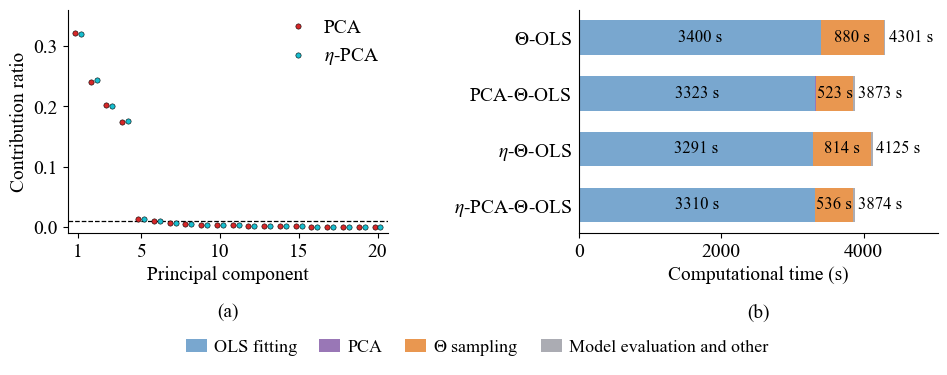

In [3]:
kl_figure()